# Backlog v4 — repeatability before calibration

E04 is a completed negative diagnostic; H44 was not fitted and is deferred.
Both cache settings fail the frozen numerical guard on identical prepared inputs.
These64known development rows are not independent quality validation. No official
submission was made; best official loss remains0.95481.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
assert (REPO/'GOAL.md').exists()
RESULTS=REPO/'results/span_004'
FIGURES=Path.home()/'database/llm_classification_finetuning/runs/span_004/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def read(name):return json.loads((RESULTS/name).read_text())
def save(fig,name):
    for extension in ['png','svg']:fig.savefig(FIGURES/(name+'.'+extension),bbox_inches='tight',dpi=160)
    plt.show()
result=read('repeatability_results.json');controls=read('diagnostic_controls.json');plan=read('span_plan.json')
registry=json.loads((REPO/'backlog/hypotheses.json').read_text())
v4=next(v for v in registry['versions'] if v['number']==4)
items={i['id']:i for i in registry['items']}
print('v4 state:',v4['state'],'original start:',plan['started_at'],'deadline:',plan['deadline'])
display(pd.DataFrame([{'task':key,'status':items[key]['status'],'title':items[key]['title']} for key in v4['focus_ids']]))
print('Coverage:',result['rows'],'rows /',result['groups'],'groups,',result['competition_scoring_requests'],'fresh requests')
print('Model identity:',result['model_identity'])


v4 state: closed original start: 2026-11-04T14:29:32+00:00 deadline: 2026-11-06T14:29:32+00:00


,task,status,title
0,E04,done,Establish a reproducible native judge scoring ...
1,H44,deferred,Calibrate a routed classifier and judge mixture


Coverage: 64 rows / 64 groups, 512 fresh requests
Model identity: {'source': 'google/gemma-4/gguf/gemma-4-26b-a4b-it-qat-q4_0-gguf/2', 'filename': 'gemma-4-26B_q4_0-it.gguf', 'bytes': 14439361440, 'sha256': '4c856523d61d77922dbc0b26753a6bf6208e5d69d80db0c04dcd776832d054c5'}


## Numerical gates, excluding competition labels

Only cache_prompt changes between configurations. Each has an initial pass,
same-order replay, fixed permutation and clean restart. IDs and full prepared
token hashes match; every response/prediction hash is checked. No parameter or
serving setting was selected from human-label losses.


,case,comparison,mean_drift,max_drift,argmax_changed_fraction,passed
0,cache_on,repeat,0.018796,0.170790,0.000000,False
1,cache_on,permuted,0.021524,0.202364,0.031250,False
2,cache_on,restart,0.023221,0.328158,0.046875,False
3,cache_off,repeat,0.020813,0.243951,0.031250,False
4,cache_off,permuted,0.027951,0.237268,0.031250,False
5,cache_off,restart,0.025487,0.208597,0.031250,False


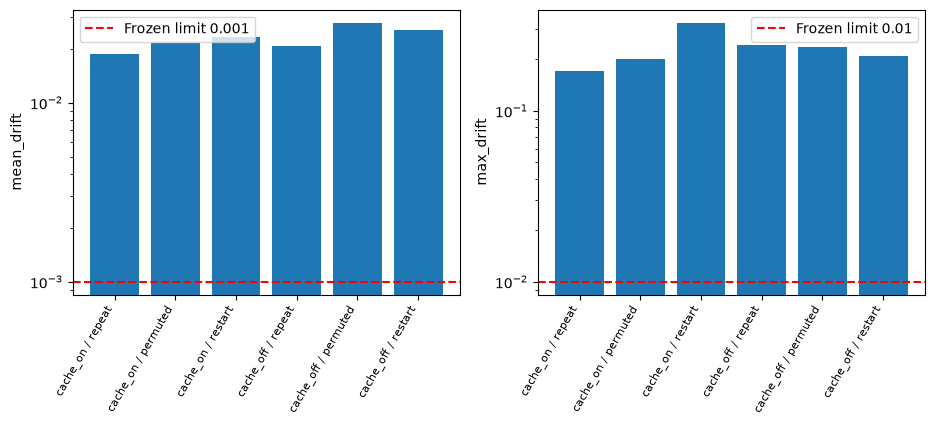

Qualified recipe: None
All cases/pass prepared token IDs are identical: True


In [2]:
rows=[]
for case,value in result['cases'].items():
    for comparison,c in value['comparisons'].items():
        rows.append({'case':case,'comparison':comparison,'mean_drift':c['mean_probability_difference'],
                     'max_drift':c['max_probability_difference'],'argmax_changed_fraction':c['argmax_disagreement'],
                     'passed':c['passed']})
stability=pd.DataFrame(rows);display(stability)
fig,axes=plt.subplots(1,2,figsize=(11,3.7));x=np.arange(len(stability));labels=stability['case']+' / '+stability['comparison']
for ax,column,limit in zip(axes,['mean_drift','max_drift'],[.001,.01]):
    ax.bar(x,stability[column]);ax.axhline(limit,color='red',linestyle='--',label=f'Frozen limit {limit}')
    ax.set_xticks(x,labels,rotation=60,ha='right',fontsize=8);ax.set_yscale('log');ax.set_ylabel(column);ax.legend()
save(fig,'raw_repeatability')
print('Qualified recipe:',result['selected_recipe'])
print('All cases/pass prepared token IDs are identical:',all(c['prepared_tokens_identical_across_every_case_and_pass'] for c in result['cases'].values()))


## Descriptive losses and constant controls

The frozen judge calibrator was fitted on a2,048-row cohort containing these64rows.
This is a numerical loss diagnostic, not independent validation. All passes are
reported; no serving setting is chosen by loss. Intervals are2,000 paired group
resamples conditional on the fixed predictions/calibrator.


,case,phase,raw_loss,fixed_calibrated_loss,raw_accuracy,calibrated_accuracy,tie_loss,tie_recall,tie_auc
0,cache_on,initial,1.402618,0.974778,0.468750,0.515625,1.189749,0.235294,0.618273
1,cache_on,repeat,1.398282,0.972934,0.468750,0.468750,1.197322,0.176471,0.602003
2,cache_on,permuted,1.413563,0.976127,0.468750,0.484375,1.216913,0.235294,0.595745
3,cache_on,restart,1.412903,0.978415,0.500000,0.468750,1.205182,0.235294,0.605757
4,cache_off,initial,1.380546,0.971255,0.468750,0.468750,1.174536,0.176471,0.622028
5,cache_off,repeat,1.401614,0.971806,0.468750,0.484375,1.205797,0.176471,0.604506
6,cache_off,permuted,1.412154,0.977028,0.468750,0.453125,1.200665,0.176471,0.622028
7,cache_off,restart,1.426676,0.980639,0.484375,0.515625,1.208414,0.235294,0.610763


,control,log_loss,accuracy,binary_tie_loss,winner_contribution
0,classifier_frozen_temperature,0.957823,0.484375,0.543815,0.414008
1,training_prior,1.091653,0.406250,0.583393,0.508260
2,majority_clipped_1e-12,16.405919,0.406250,7.339490,9.066429
3,uniform,1.098612,0.406250,0.589582,0.509030


Human class counts: [26, 21, 17]
Exact one-hot loss is infinite on errors; the table explicitly clips at1e-12. Uniform argmax ties resolve to A.
Classifier raw-order disagreement: 0.21875


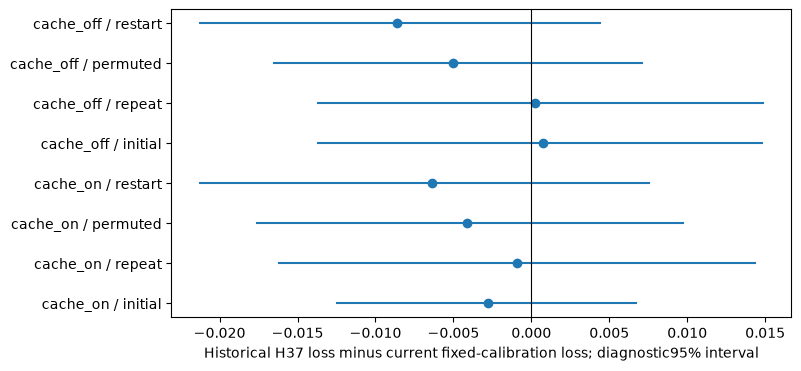

In [3]:
quality=[]
for case,value in result['cases'].items():
    for phase,p in value['passes'].items():
        quality.append({'case':case,'phase':phase,'raw_loss':p['raw_metrics']['log_loss'],
                        'fixed_calibrated_loss':p['fixed_calibration_metrics']['log_loss'],
                        'raw_accuracy':p['raw_metrics']['accuracy'],'calibrated_accuracy':p['fixed_calibration_metrics']['accuracy'],
                        'tie_loss':p['fixed_calibration_metrics']['class_loss'][2],
                        'tie_recall':p['fixed_calibration_metrics']['class_recall'][2],
                        'tie_auc':p['fixed_calibration_metrics']['tie_auc']})
display(pd.DataFrame(quality))
display(pd.DataFrame([{'control':name,'log_loss':v['log_loss'],'accuracy':v['accuracy'],
                      'binary_tie_loss':v['loss_channels']['binary_tie_log_loss'],
                      'winner_contribution':v['loss_channels']['conditional_winner_contribution']}
                     for name,v in controls['controls'].items()]))
print('Human class counts:',controls['class_counts']);print(controls['hard_majority_note'])
print('Classifier raw-order disagreement:',controls['classifier_raw_order_disagreement'])
fig,ax=plt.subplots(figsize=(8,4));labels=[]
for index,row in enumerate(quality):
    value=result['cases'][row['case']]['passes'][row['phase']]['fixed_calibration_loss_effect']
    lo,hi=value['interval_95'];ax.plot([lo,hi],[index,index],color='C0');ax.scatter(value['gain'],index,color='C0')
    labels.append(row['case']+' / '+row['phase'])
ax.set_yticks(range(len(labels)),labels);ax.axvline(0,color='black',linewidth=.8)
ax.set_xlabel('Historical H37 loss minus current fixed-calibration loss; diagnostic95% interval')
save(fig,'loss_drift_diagnostic')


## Runtime, memory and actual compute

Projection assumes25,000 hidden rows and20%routed, includes20%inference margin,
600sreserve and measured setup. Cases always ran cache_on then cache_off, so
timing is not counterbalanced. No passing numerical/runtime combination exists.
Sampled device-used memory is not allocator peak memory.


,case,judge_seconds_per_row,cascade_seconds,runtime_pass,stability_pass,memory_mib
0,cache_on,1.192791,26328.597069,False,False,"[9551, 8833]"
1,cache_off,0.884327,24477.816837,True,False,"[9551, 8833]"


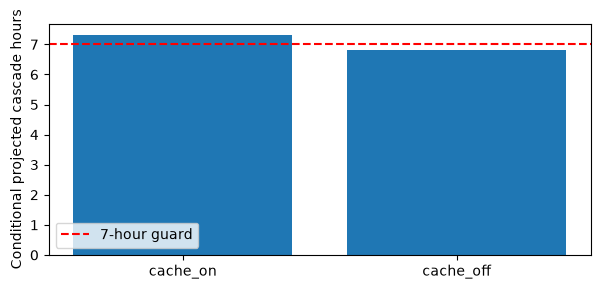

Sampled total device-used MiB including runtime/driver, not allocator peak.
Setup allowance: 395.90864416327304 seconds
Retry notebook session: 783.7562580108643 seconds
Retry charged: 801.8500000000058 total charged: 839.252999999997 seconds
Original cap: 29337.998999999996 seconds
Manifest guard correction: {'failure': 'Serialized JSON package-key ordering differs; all parsed fields and175 file hashes/sizes are equal.', 'parsed_manifests_equal': True, 'changed_file_records': 0, 'files': 175, 'original_byte_sha256': '0de4e0738d3493621a0369487bc7c6222597e6fe700327555537c9afd7cba2b9', 'observed_byte_sha256': '0f3a224a7ee235a4efc4c8b88ed2b3937da079bc36d154e8f47a40bad0c389ca', 'canonical_sha256': 'a3faba4f5e96d9dcab552adbecf5ef8aedc3f21239a0e0bf78384d702775ca0d', 'failed_before_model_inference': True, 'competition_scoring_requests': 0, 'original_charge_seconds': 37.40299999999115, 'original_diagnostic_stage_seconds_cap': 1800, 'retry_seconds_cap': 1680, 'finalization_reserve_seconds': 60,

In [4]:
runtime=pd.DataFrame([{'case':name,'judge_seconds_per_row':v['conservative_judge_seconds_per_row'],
            'cascade_seconds':v['projected_cascade_seconds'],'runtime_pass':v['runtime_guard_passed'],
            'stability_pass':v['repeatability_passed'],'memory_mib':v['sampled_device_used_peak_mib']}
           for name,v in result['cases'].items()]);display(runtime)
fig,ax=plt.subplots(figsize=(7,3));ax.bar(runtime['case'],runtime['cascade_seconds']/3600)
ax.axhline(7,color='red',linestyle='--',label='7-hour guard');ax.set_ylabel('Conditional projected cascade hours');ax.legend()
save(fig,'runtime_guard')
print(result['memory_note']);print('Setup allowance:',result['joint_setup_allowance_seconds'],'seconds')
print('Retry notebook session:',result['session_seconds'],'seconds')
print('Retry charged:',result['charged_seconds'],'total charged:',result['span_charged_seconds'],'seconds')
print('Original cap:',plan['gpu_session_seconds_cap'],'seconds')
print('Manifest guard correction:',read('manifest_guard_recovery.json'))
print('Read-only retrieval recovery:',{k:v for k,v in read('jobs/repeatability_retry/retrieval_recovery.json').items() if k!='artifact_sha256'})


## Stopping decision and versioned handoff

H44's three-family comparison, uniform fitting rescore and new-group check remain
unexecuted because E04 failed. Carry H44 forward with an explicit prerequisite;
request concurrency is a new hypothesis, not an established cause. Preserve all
old caches, source/failed-run evidence and original clocks. Stop before v5 work.


In [5]:
for name in ['decisions.json','terminal_audit.json']:
    if (RESULTS/name).exists():print(name,read(name))
display(pd.DataFrame([{'version':v['number'],'state':v['state'],'tasks':len(v['item_ids']),'focus':v['focus_ids']}
                      for v in registry['versions']]))
print('Official score unchanged:',result['official_score_unchanged'])
print('Figures:',FIGURES)


decisions.json {'span': 4, 'generated_at': '2026-11-04T16:31:25.980919+00:00', 'E04': {'status': 'done', 'outcome': 'negative numerical qualification', 'diagnostic_completed': True, 'native_hardware_passed': True, 'passing_recipes': []}, 'H44': {'status': 'deferred', 'model_comparison_executed': False, 'reason': 'Neither fixed native recipe passes repeatability. Runtime alone is insufficient; require E05 qualification and a consistent cache before fitting.'}, 'uniform_fitting_rescore_executed': False, 'new_group_check_executed': False, 'joint_profile_executed': False, 'new_official_submissions': 0, 'best_official_score': 0.95481, 'queued_followup': 'E05', 'serving_settings_selected_by_human_label_loss': False, 'confirmation_used': False, 'total_charged_seconds': 839.252999999997, 'within_original_caps': True, 'source_sha256': '5291280a7495623ae32811503c8dd4bd922b584628ffdc427c76eeebd6c1b9f7', 'input_sha256': {'repeatability_results.json': '4fe3db62d698c33a5f212ecbe1ee2067a3cff5577b1ba9

,version,state,tasks,focus
0,1,closed,41,"[E00, H01, H09, H04, H11]"
1,2,closed,39,"[H40, E01, H03, H37, H42]"
2,3,closed,37,"[E03, H39, E02, H43]"
3,4,closed,35,"[E04, H44]"
4,5,active,35,[]
5,6,draft,0,[]


Official score unchanged: 0.95481
Figures: /home/tarstars/database/llm_classification_finetuning/runs/span_004/figures
